## Step 1 — Set up the data lake and build the Bronze layer

In [35]:
import os, re, html, zipfile, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)

# Data lake folders
for layer in ["bronze", "silver", "gold"]:
    os.makedirs(layer, exist_ok=True)
os.makedirs("raw", exist_ok=True)
print("Folders:", [d for d in ["raw", "bronze", "silver", "gold"] if os.path.isdir(d)])

Folders: ['raw', 'bronze', 'silver', 'gold']


In [36]:
URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
if not all(os.path.exists(f"raw/{f}") for f in ["BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv"]):
    urllib.request.urlretrieve(URL, "raw/book-crossings.zip")
    with zipfile.ZipFile("raw/book-crossings.zip") as z:
        z.extractall("raw")
print(sorted(os.listdir("raw")))

['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
READ_KW = dict(sep=";", encoding="latin-1", escapechar="\\", on_bad_lines="skip", dtype=str)
users   = pd.read_csv("raw/BX-Users.csv", **READ_KW)
books   = pd.read_csv("raw/BX-Books.csv", **READ_KW)
ratings = pd.read_csv("raw/BX-Book-Ratings.csv", **READ_KW)

ts = pd.Timestamp.now(tz="UTC")           # one ingestion time for the whole batch
for name, df in [("users", users), ("books", books), ("ratings", ratings)]:
    df["ingestion_timestamp"] = ts
    df.to_parquet(f"bronze/{name}.parquet", index=False)   # no cleaning at all
    print(f"bronze/{name}.parquet  rows={len(df):,}")

bronze/users.parquet  rows=278,858
bronze/books.parquet  rows=271,379
bronze/ratings.parquet  rows=1,149,780


## Step 2 — Explore the Bronze data (EDA)

In [39]:
bu = pd.read_parquet("bronze/users.parquet")
bb = pd.read_parquet("bronze/books.parquet")
br = pd.read_parquet("bronze/ratings.parquet")
for name, df in [("users", bu), ("books", bb), ("ratings", br)]:
    print(f"=== {name}: shape {df.shape}")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
    print()

=== users: shape (278858, 4)
                                   dtype  missing
User-ID                           object        0
Location                          object        0
Age                               object   110762
ingestion_timestamp  datetime64[us, UTC]        0

=== books: shape (271379, 9)
                                   dtype  missing
ISBN                              object        0
Book-Title                        object        0
Book-Author                       object        2
Year-Of-Publication               object        0
Publisher                         object        2
Image-URL-S                       object        0
Image-URL-M                       object        0
Image-URL-L                       object        0
ingestion_timestamp  datetime64[us, UTC]        0

=== ratings: shape (1149780, 4)
                                   dtype  missing
User-ID                           object        0
ISBN                              object        0
Book-Rat

**EDA 1 – Shape, dtypes, missing values.** Users 278,858 × 4, Books 271,379 × 9, Ratings 1,149,780 × 4 (incl. `ingestion_timestamp`). Every source column is a string because Bronze is raw. Only `Age` has many nulls (≈110,762, ~40%); `Book-Author` and `Publisher` have 2 nulls each. → *Silver:* cast `Age`, `Year-Of-Publication`, `Book-Rating` to numbers; impute age with the median; leave the few missing authors/publishers as "Unknown".

rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610

Zero ratings: 716,109 of 1,149,780 = 62.3%


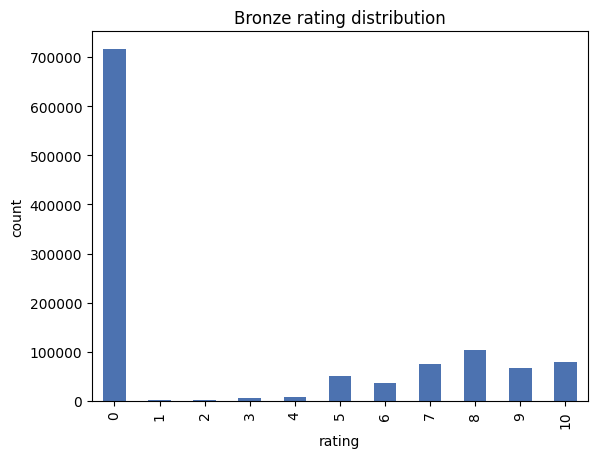

In [40]:
br["rating"] = br["Book-Rating"].astype(int)
vc = br["rating"].value_counts().sort_index()
print(vc.to_string())
print(f"\nZero ratings: {(br.rating==0).sum():,} of {len(br):,} = {(br.rating==0).mean():.1%}")
vc.plot(kind="bar", title="Bronze rating distribution", color="#4c72b0"); plt.xlabel("rating"); plt.ylabel("count"); plt.show()

**EDA 2 – Ratings.** About **716,109 of 1,149,780 (62%)** ratings are `0`, which means *implicit / no explicit rating*, not "hated it". Explicit ratings (1–10) are skewed high (8 is the mode, 10 and 7 next). → *Silver:* drop all 0s and keep 1–10 only.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Age < 5: 882 | Age > 100: 366 | max age: 244
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year == 0: 4,619 | Year > 2026: 11 | min non-zero: 1376


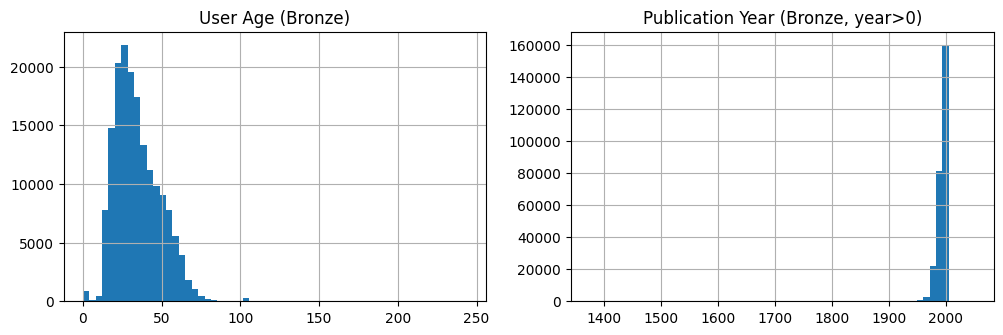

In [41]:
age = pd.to_numeric(bu["Age"], errors="coerce")
print(age.describe())
print(f"Age < 5: {(age<5).sum():,} | Age > 100: {(age>100).sum():,} | max age: {age.max():.0f}")
year = pd.to_numeric(bb["Year-Of-Publication"], errors="coerce")
print(year.describe())
print(f"Year == 0: {(year==0).sum():,} | Year > 2026: {(year>2026).sum():,} | min non-zero: {year[year>0].min():.0f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
age.dropna().clip(upper=250).hist(bins=60, ax=ax[0]); ax[0].set_title("User Age (Bronze)")
year[year>0].hist(bins=60, ax=ax[1]); ax[1].set_title("Publication Year (Bronze, year>0)")
plt.show()

**EDA 3 – Ages and years.** Ages run from 0 to 244; 882 users are < 5 and 366 are > 100 (impossible, plus ages like 0/1/244). Publication year has **4,619 zeros** and 11 future years (up to 2050), with some very old values too. → *Silver:* ages < 5 or > 100 → null → fill with the median (≈32); years of 0 or > current year (4,630 values) → null (kept as nullable, not imputed, since the year is not used by the model).

Ratings per user:
 count    105283.0
mean         10.9
std          90.6
min           1.0
50%           1.0
75%           4.0
90%          12.0
99%         174.0
max       13602.0

Ratings per book:
 count    340556.0
mean          3.4
std          12.4
min           1.0
50%           1.0
75%           2.0
90%           6.0
99%          36.0
max        2502.0


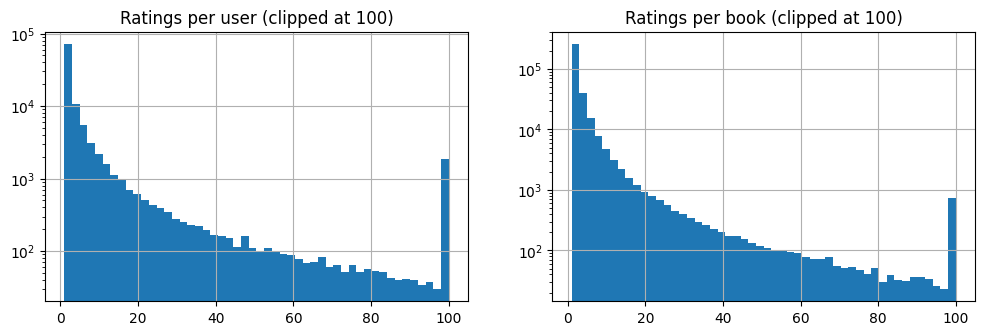


Explicit (1-10) ratings only: users/books with >= k ratings
 k  users>=k  books>=k
 1     77805    185973
 5     14220     14535
10      7334      5645
20      3704      2179
50      1332       537


In [42]:
upr = br.groupby("User-ID").size(); bpr = br.groupby("ISBN").size()
print("Ratings per user:\n", upr.describe(percentiles=[.5,.75,.9,.99]).round(1).to_string())
print("\nRatings per book:\n", bpr.describe(percentiles=[.5,.75,.9,.99]).round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
upr.clip(upper=100).hist(bins=50, ax=ax[0], log=True); ax[0].set_title("Ratings per user (clipped at 100)")
bpr.clip(upper=100).hist(bins=50, ax=ax[1], log=True); ax[1].set_title("Ratings per book (clipped at 100)")
plt.show()
exp = br[br.rating > 0]
euc = exp.groupby("User-ID").size(); ebc = exp.groupby("ISBN").size()
print("\nExplicit (1-10) ratings only: users/books with >= k ratings")
print(pd.DataFrame({"k": [1,5,10,20,50],
    "users>=k": [(euc>=k).sum() for k in [1,5,10,20,50]],
    "books>=k": [(ebc>=k).sum() for k in [1,5,10,20,50]]}).to_string(index=False))

**EDA 4 – Long tail.** The median user and the median book each have just **1 rating** (mean 10.9 per user, 3.4 per book, but max 13,602 for one user and 2,502 for one book). Most users/books are far too sparse for a similarity measure. Among explicit ratings, only 7,334 users and 5,645 books have ≥ 10 ratings (14,220 / 14,535 at ≥ 5; 3,704 / 2,179 at ≥ 20). → *Silver:* **minimum 10 ratings per user and per book** (justified below).

In [43]:
n_u, n_b, n_r = len(bu), len(bb), len(br)
print(f"Possible user-book pairs (users table x books table): {n_u*n_b:,}")
print(f"Actual ratings (all rows): {n_r:,}  -> density {n_r/(n_u*n_b):.5%}, sparsity {1-n_r/(n_u*n_b):.5%}")
ur, bk = br["User-ID"].nunique(), br["ISBN"].nunique()
print(f"Using only users/books that appear in ratings ({ur:,} x {bk:,}): density {n_r/(ur*bk):.5%}")
print(f"Explicit ratings only: density {len(exp)/(ur*bk):.5%}")
print(f"Ratings whose ISBN is missing from Books: {(~br.ISBN.isin(bb.ISBN)).mean():.1%}")

Possible user-book pairs (users table x books table): 75,676,205,182
Actual ratings (all rows): 1,149,780  -> density 0.00152%, sparsity 99.99848%
Using only users/books that appear in ratings (105,283 x 340,556): density 0.00321%
Explicit ratings only: density 0.00121%
Ratings whose ISBN is missing from Books: 10.3%


**EDA 5 – Sparsity.** The full matrix is **99.998% empty** (only ~0.0015% of user-book pairs are rated). A dense matrix would need tens of billions of cells, so Gold must use a **sparse (CSR) matrix**. Also ~10% of rating rows point to ISBNs that are absent from the Books table. → *Silver:* keep only ratings whose user and book exist in the Users and Books tables.

**Threshold choice (min 10 ratings).** The median user/book has 1 rating, so a low cutoff would keep thousands of near-empty vectors where cosine similarity is noise (two books sharing one reader look "100% similar"). Raising to 20 shrinks the book set to ~2,200, losing too much catalogue. **10** is the knee point: on explicit ratings alone it passes ~7.3k users and ~5.6k books, each with enough co-ratings for cosine similarity to mean something, while keeping a usable catalogue. After the integrity join and iterating to a stable set, Silver ends at 1,820 users, 2,030 books and 41,469 ratings. Because removing users lowers book counts (and vice-versa), the filter is applied **iteratively until stable**.

## Step 3 — Clean the data and build the Silver layer

In [44]:
MIN_RATINGS = 10                       # threshold chosen from EDA
CURRENT_YEAR = pd.Timestamp.now().year

def smart_title(s):
    """Title-case without the .title() apostrophe bug ("Don'T"). Also unescapes HTML entities."""
    if pd.isna(s): return s
    s = html.unescape(str(s))
    s = re.sub(r"\s+", " ", s).strip().lower()
    return re.sub(r"(^|[\s\-\(\"/&])([a-z])", lambda m: m.group(1) + m.group(2).upper(), s)

s_users, s_books, s_ratings = (pd.read_parquet(f"bronze/{n}.parquet") for n in ["users", "books", "ratings"])
log = {"users": [len(s_users)], "books": [len(s_books)], "ratings": [len(s_ratings)]}

In [45]:
# Remove duplicates (full-row, then on the natural keys)
s_users   = s_users.drop(columns="ingestion_timestamp").drop_duplicates().drop_duplicates("User-ID")
s_books   = s_books.drop(columns="ingestion_timestamp").drop_duplicates().drop_duplicates("ISBN")
s_ratings = s_ratings.drop(columns="ingestion_timestamp").drop_duplicates().drop_duplicates(["User-ID", "ISBN"])
print("after dedupe:", len(s_users), len(s_books), len(s_ratings))

# Ratings: numeric, keep 1..10 only (0 = no explicit rating)
s_ratings["Book-Rating"] = pd.to_numeric(s_ratings["Book-Rating"], errors="coerce")
s_ratings = s_ratings[s_ratings["Book-Rating"].between(1, 10)].copy()
s_ratings["Book-Rating"] = s_ratings["Book-Rating"].astype("int8")
print("after removing 0 ratings:", len(s_ratings))

after dedupe: 278858 271379 1149780
after removing 0 ratings: 433671


In [46]:
# User ages: <5 or >100 -> null -> fill with median
s_users["Age"] = pd.to_numeric(s_users["Age"], errors="coerce")
s_users.loc[(s_users.Age < 5) | (s_users.Age > 100), "Age"] = np.nan
median_age = s_users["Age"].median()
s_users["Age"] = s_users["Age"].fillna(median_age).astype("int16")
print("median age used:", median_age, "| age range now:", s_users.Age.min(), "-", s_users.Age.max())

# Split Location -> city, state, country ("city, state, country")
parts = s_users["Location"].fillna("").str.split(",", expand=True)
parts = parts.reindex(columns=range(3))
s_users["city"], s_users["state"], s_users["country"] = parts[0], parts[1], parts[2]
for c in ["city", "state", "country"]:
    s_users[c] = s_users[c].map(lambda v: smart_title(v) if isinstance(v, str) else v)
    s_users[c] = s_users[c].replace({"": np.nan, "N/A": np.nan, "N/a": np.nan})
s_users = s_users.drop(columns="Location")
s_users["User-ID"] = s_users["User-ID"].astype("int64")
s_ratings["User-ID"] = s_ratings["User-ID"].astype("int64")
print(s_users.head())

median age used: 32.0 | age range now: 5 - 100
   User-ID  Age         city            state         country
0        1   32          Nyc         New York             Usa
1        2   18     Stockton       California             Usa
2        3   32       Moscow  Yukon Territory          Russia
3        4   17        Porto         V.n.gaia        Portugal
4        5   32  Farnborough            Hants  United Kingdom


In [47]:
# Publication year: 0 or future -> null (nullable Int)
s_books["Year-Of-Publication"] = pd.to_numeric(s_books["Year-Of-Publication"], errors="coerce")
bad = (s_books["Year-Of-Publication"] == 0) | (s_books["Year-Of-Publication"] > CURRENT_YEAR)
print("years set to null:", int(bad.sum()))
s_books.loc[bad, "Year-Of-Publication"] = np.nan
s_books["Year-Of-Publication"] = s_books["Year-Of-Publication"].astype("Int16")

# Text columns: trim spaces, standardise case, drop image-URL columns
s_books = s_books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
for c in ["Book-Title", "Book-Author", "Publisher"]:
    s_books[c] = s_books[c].map(smart_title)
s_books["Book-Author"] = s_books["Book-Author"].fillna("Unknown")
s_books["Publisher"]   = s_books["Publisher"].fillna("Unknown")
s_books["ISBN"] = s_books["ISBN"].str.strip().str.upper()
s_ratings["ISBN"] = s_ratings["ISBN"].str.strip().str.upper()
s_books = s_books.drop_duplicates("ISBN")
print(s_books.head())

years set to null: 4630
         ISBN                                                   Book-Title           Book-Author  Year-Of-Publication                Publisher
0  0195153448                                          Classical Mythology    Mark P. O. Morford                 2002  Oxford University Press
1  0002005018                                                 Clara Callan  Richard Bruce Wright                 2001    Harperflamingo Canada
2  0060973129                                         Decision In Normandy          Carlo D'este                 1991          Harperperennial
3  0374157065  Flu: The Story Of The Great Influenza Pandemic Of 1918 A...      Gina Bari Kolata                 1999     Farrar Straus Giroux
4  0393045218                                       The Mummies Of Urumchi       E. J. W. Barber                 1999   W. W. Norton & Company


In [48]:
# Referential integrity: ratings must reference an existing user and book
before = len(s_ratings)
s_ratings = s_ratings[s_ratings["User-ID"].isin(s_users["User-ID"]) & s_ratings["ISBN"].isin(s_books["ISBN"])]
print(f"ratings dropped (orphan user/book): {before-len(s_ratings):,}")

# Minimum activity threshold, applied until stable
while True:
    n0 = len(s_ratings)
    uc = s_ratings["User-ID"].map(s_ratings["User-ID"].value_counts())
    s_ratings = s_ratings[uc >= MIN_RATINGS]
    bc = s_ratings["ISBN"].map(s_ratings["ISBN"].value_counts())
    s_ratings = s_ratings[bc >= MIN_RATINGS]
    if len(s_ratings) == n0: break
s_users = s_users[s_users["User-ID"].isin(s_ratings["User-ID"])]
s_books = s_books[s_books["ISBN"].isin(s_ratings["ISBN"])]
s_users, s_books, s_ratings = (d.reset_index(drop=True) for d in (s_users, s_books, s_ratings))

for n, d in [("users", s_users), ("books", s_books), ("ratings", s_ratings)]:
    d.to_parquet(f"silver/{n}.parquet", index=False)
print(f"SILVER  users={len(s_users):,}  books={len(s_books):,}  ratings={len(s_ratings):,}")
print(f"Silver matrix density: {len(s_ratings)/(len(s_users)*len(s_books)):.3%}")

ratings dropped (orphan user/book): 49,818
SILVER  users=1,820  books=2,030  ratings=41,469
Silver matrix density: 1.122%


## Step 4 — Build the Gold layer

In [49]:
g_users, g_books, g_ratings = (pd.read_parquet(f"silver/{n}.parquet") for n in ["users", "books", "ratings"])

# Integer indexes for the sparse matrix
user_ids = np.sort(g_ratings["User-ID"].unique()); isbns = np.sort(g_ratings["ISBN"].unique())
u_idx = pd.Series(np.arange(len(user_ids)), index=user_ids); b_idx = pd.Series(np.arange(len(isbns)), index=isbns)

# (1) Sparse user x book rating matrix (CSR)
R = sp.csr_matrix((g_ratings["Book-Rating"].astype("float32"),
                   (u_idx[g_ratings["User-ID"]].values, b_idx[g_ratings["ISBN"]].values)),
                  shape=(len(user_ids), len(isbns)))
sp.save_npz("gold/user_book_matrix.npz", R)
pd.DataFrame({"row": np.arange(len(user_ids)), "User-ID": user_ids}).to_parquet("gold/user_index.parquet", index=False)
pd.DataFrame({"col": np.arange(len(isbns)), "ISBN": isbns}).to_parquet("gold/book_index.parquet", index=False)

# (2) Book lookup (id, title, author)
book_lookup = g_books[["ISBN", "Book-Title", "Book-Author"]].rename(
    columns={"ISBN": "book_id", "Book-Title": "title", "Book-Author": "author"})
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# (3) Aggregates
user_agg = g_ratings.groupby("User-ID")["Book-Rating"].agg(avg_rating="mean", n_ratings="count").round(3).reset_index()
book_agg = g_ratings.groupby("ISBN")["Book-Rating"].agg(avg_rating="mean", n_ratings="count").round(3).reset_index()
user_agg.to_parquet("gold/user_aggregates.parquet", index=False)
book_agg.to_parquet("gold/book_aggregates.parquet", index=False)

print(f"Matrix {R.shape}, nnz={R.nnz:,}, density={R.nnz/np.prod(R.shape):.3%}, memory={(R.data.nbytes+R.indices.nbytes+R.indptr.nbytes)/1e6:.1f} MB")
print(sorted(os.listdir("gold")))
book_agg.merge(book_lookup, left_on="ISBN", right_on="book_id").sort_values("n_ratings", ascending=False).head(5)[["title","author","avg_rating","n_ratings"]]

Matrix (1820, 2030), nnz=41,469, density=1.122%, memory=0.3 MB
['book_aggregates.parquet', 'book_index.parquet', 'book_lookup.parquet', 'user_aggregates.parquet', 'user_book_matrix.npz', 'user_index.parquet']


,title,author,avg_rating,n_ratings
281,The Lovely Bones: A Novel,Alice Sebold,8.238,223
662,The Da Vinci Code,Dan Brown,8.610,177
205,The Red Tent (Bestselling Backlist),Anita Diamant,8.492,132
176,The Secret Life Of Bees,Sue Monk Kidd,8.664,125
1520,Harry Potter And The Sorcerer's Stone (Harry Potter (Pap...,J. K. Rowling,9.042,119


## Step 5 — Item-based collaborative filtering

In [50]:
# 1. Load matrix from Gold; rows = books, columns = users
R = sp.load_npz("gold/user_book_matrix.npz")
user_index = pd.read_parquet("gold/user_index.parquet"); book_index = pd.read_parquet("gold/book_index.parquet")
lookup = pd.read_parquet("gold/book_lookup.parquet").set_index("book_id")
B = R.T.tocsr()
isbn_of = book_index["ISBN"].values; col_of_isbn = pd.Series(book_index["col"].values, index=isbn_of)
uid_to_row = pd.Series(user_index["row"].values, index=user_index["User-ID"].values)
title_of = lambda col: lookup.loc[isbn_of[col], "title"]
print("Book x user matrix:", B.shape)

# 2. Cosine similarity via NearestNeighbors (brute force works on sparse input)
K = 50
nn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=K + 1).fit(B)

Book x user matrix: (2030, 1820)


In [51]:
# 3. Similar books by title
title_series = lookup.loc[isbn_of, "title"].reset_index(drop=True)
pop = np.asarray((B > 0).sum(axis=1)).ravel()

def find_book(title):
    t = title.strip().lower()
    exact = np.where(title_series.str.lower().values == t)[0]
    if len(exact) == 0:
        exact = np.where(title_series.str.lower().str.contains(re.escape(t)).values)[0]
    if len(exact) == 0: raise ValueError(f"No book matching '{title}'")
    return exact[np.argmax(pop[exact])]

def similar_books(title, n=10):
    i = find_book(title)
    dist, idx = nn.kneighbors(B[i], n_neighbors=min(K + 1, B.shape[0]))
    out, seen = [], {title_series[i].lower()}
    for d, j in zip(dist[0], idx[0]):
        t = title_series[j]
        if j == i or t.lower() in seen: continue
        seen.add(t.lower()); out.append((t, lookup.loc[isbn_of[j], "author"], round(1 - d, 3)))
        if len(out) == n: break
    print(f"Books similar to: {title_series[i]}")
    return pd.DataFrame(out, columns=["title", "author", "cosine_similarity"])

similar_books("The Lovely Bones: A Novel")

Books similar to: The Lovely Bones: A Novel


,title,author,cosine_similarity
0,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.219
1,Lucky : A Memoir,Alice Sebold,0.218
2,The Da Vinci Code,Dan Brown,0.178
3,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,Good In Bed,Jennifer Weiner,0.176
5,Nights In Rodanthe,Nicholas Sparks,0.170
6,The Pact: A Love Story,Jodi Picoult,0.168
7,The Lake House,James Patterson,0.166
8,Lucky,Alice Sebold,0.165
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


In [52]:
# 4. recommend(user_id, n): similarity weighted by the user's own rating
def user_liked(user_id, min_rating=8):
    row = R[uid_to_row[user_id]]
    cols, vals = row.indices, row.data
    return cols[vals >= min_rating], vals[vals >= min_rating]

def recommend(user_id, n=10, min_rating=8):
    if user_id not in uid_to_row.index: raise KeyError(f"User {user_id} is not in the Gold layer")
    seen = set(R[uid_to_row[user_id]].indices)
    liked_cols, liked_vals = user_liked(user_id, min_rating)
    if len(liked_cols) == 0: return pd.DataFrame(columns=["title", "author", "score"])
    dist, idx = nn.kneighbors(B[liked_cols], n_neighbors=K + 1)
    scores = {}
    for r_val, d_row, i_row in zip(liked_vals, dist, idx):
        for d, j in zip(d_row, i_row):
            if j in seen: continue
            scores[j] = scores.get(j, 0.0) + (1 - d) * r_val
    top = sorted(scores.items(), key=lambda x: -x[1])
    out, titles = [], set()
    for j, s in top:
        t = title_series[j]
        if t.lower() in titles: continue
        titles.add(t.lower()); out.append((t, lookup.loc[isbn_of[j], "author"], round(s, 2)))
        if len(out) == n: break
    return pd.DataFrame(out, columns=["title", "author", "score"])

## Step 6 — Demo and sanity check

In [53]:
def show(user_id, n=10):
    liked_cols, liked_vals = user_liked(user_id)
    liked = pd.DataFrame({"title": [title_of(c) for c in liked_cols], "your_rating": liked_vals.astype(int)})
    print(f"\n{'='*90}\nUSER {user_id}  |  {R[uid_to_row[user_id]].nnz} books rated, {len(liked)} rated >= 8")
    print("\n-- Books this user rated highly (top 10 shown) --")
    print(liked.sort_values("your_rating", ascending=False).head(10).to_string(index=False))
    print("\n-- Recommendations --")
    print(recommend(user_id, n).to_string(index=False))

ua = pd.read_parquet("gold/user_aggregates.parquet")
rng = np.random.RandomState(42)
candidates = ua[(ua.n_ratings.between(15, 60)) & (ua.avg_rating.between(6.5, 9))]["User-ID"].values
demo_users = rng.choice(candidates, 3, replace=False)
for u in demo_users: show(int(u))


USER 244277  |  15 books rated, 5 rated >= 8

-- Books this user rated highly (top 10 shown) --
                                                                   title  your_rating
                                                 The Secret Life Of Bees            9
Politically Correct Bedtime Stories: Modern Tales For Our Life And Times            8
                                                                Quentins            8
           The Color Of Water: A Black Man's Tribute To His White Mother            8
       Eats, Shoots & Leaves: The Zero Tolerance Approach To Punctuation            8

-- Recommendations --
                                                  title                 author  score
                                             Blue Diary          Alice Hoffman   3.24
    Tears Of The Giraffe (No.1 Ladies Detective Agency) Alexander Mccall Smith   2.76
                      Standing In The Rainbow : A Novel           Fannie Flagg   2.72
                    

In [54]:
# Extra sanity check: recommendations should never include a book the user already rated
for u in demo_users:
    rec_titles = set(recommend(int(u), 10)["title"].str.lower())
    read_titles = set(title_series[R[uid_to_row[int(u)]].indices].str.lower())
    print(f"user {u}: overlap with already-read = {len(rec_titles & read_titles)} (expected 0)")

user 244277: overlap with already-read = 0 (expected 0)
user 236058: overlap with already-read = 0 (expected 0)
user 28204: overlap with already-read = 0 (expected 0)
